# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [17]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "Nosulko"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [18]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [19]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [20]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## 2. Your model

You can use any model or library, from the course or outside it, with or without the weather forecast.
Add your validation scores to `results`, so that they sit next to the benchmark's.

When you have chosen a model, fit it on the whole history and forecast the 48 hours after the end of
`data` in the submission cell below.

In [21]:
%pip install -q catboost

In [22]:

# ============================================================
# MODEL: Seasonal Regression + CatBoost Residuals
# Point forecast + calibrated 95% prediction intervals
# ============================================================

from catboost import CatBoostRegressor
import numpy as np
import pandas as pd


# ============================================================
# 1. FEATURE ENGINEERING
# ============================================================

WEATHER_COLS = [
    "cloud_cover",
    "temperature",
    "wind_speed",
    "pressure",
    "humidity",
    "daylight",
    "air_density"
]


def make_features(df, i):

    row = df.iloc[i]
    ds = row["ds"]

    features = {}

    # Calendar features
    features["hour"] = ds.hour
    features["dayofweek"] = ds.dayofweek
    features["dayofyear"] = ds.dayofyear
    features["month"] = ds.month

    # Cyclical encoding
    features["hour_sin"] = np.sin(
        2 * np.pi * ds.hour / 24
    )

    features["hour_cos"] = np.cos(
        2 * np.pi * ds.hour / 24
    )

    features["dayofyear_sin"] = np.sin(
        2 * np.pi * ds.dayofyear / 365.25
    )

    features["dayofyear_cos"] = np.cos(
        2 * np.pi * ds.dayofyear / 365.25
    )

    # Seasonal baseline
    features["seasonal_baseline"] = df["y"].iloc[i - 24]

    # Historical lags
    features["lag_48"] = df["y"].iloc[i - 48]
    features["lag_168"] = df["y"].iloc[i - 168]

    # Historical change
    features["change_24"] = (
        df["y"].iloc[i - 24] -
        df["y"].iloc[i - 48]
    )

    # Weather features
    for col in WEATHER_COLS:
        features[col] = row[col]

    return features


# ============================================================
# 2. PREPARE TRAINING DATA
# ============================================================

def make_training_data(df):

    df = df.copy().reset_index(drop=True)

    X = []
    residuals = []

    for i in range(168, len(df)):

        features = make_features(df, i)

        residual = (
            df["y"].iloc[i] -
            df["y"].iloc[i - 24]
        )

        X.append(features)
        residuals.append(residual)

    X = pd.DataFrame(X)

    residuals = np.asarray(
        residuals,
        dtype=float
    )

    return X, residuals


# ============================================================
# 3. FIT CATBOOST RESIDUAL MODEL
# ============================================================

def fit_residual_model(history):

    X_train, residuals = make_training_data(history)

    model = CatBoostRegressor(
        iterations=600,
        depth=5,
        learning_rate=0.03,
        loss_function="RMSE",
        l2_leaf_reg=5,
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        residuals
    )

    return model


# ============================================================
# 4. FORECAST
# ============================================================

def forecast_residual_model(
    history,
    future_weather,
    model
):

    history = (
        history.copy()
        .reset_index(drop=True)
    )

    future_weather = (
        future_weather.copy()
        .reset_index(drop=True)
    )

    predictions = []

    for i in range(len(future_weather)):

        # Daily seasonal baseline
        baseline = history["y"].iloc[-24]

        future_row = future_weather.iloc[i]

        new_row = {
            "ds": future_row["ds"],
            "y": baseline
        }

        for col in WEATHER_COLS:
            new_row[col] = future_row[col]

        history = pd.concat(
            [
                history,
                pd.DataFrame([new_row])
            ],
            ignore_index=True
        )

        current_index = len(history) - 1

        # Generate features
        X_future = pd.DataFrame([
            make_features(
                history,
                current_index
            )
        ])

        # Predict residual
        residual_prediction = float(
            model.predict(X_future)[0]
        )

        # Correct seasonal baseline
        prediction = (
            baseline +
            residual_prediction
        )

        # Non-negative generation
        prediction = max(
            0.0,
            prediction
        )

        predictions.append(prediction)

        # Store prediction for recursive lags
        history.loc[
            current_index,
            "y"
        ] = prediction

    return np.asarray(
        predictions,
        dtype=float
    )


# ============================================================
# 5. ROLLING VALIDATION
# ============================================================

H = 48

OFFSETS = [168, 336, 672]

validation_results = []

validation_errors = []

for offset in OFFSETS:

    history = data.iloc[:-offset].copy()

    valid = data.iloc[
        -offset:-offset + H
    ].copy()

    model = fit_residual_model(history)

    pred = forecast_residual_model(
        history,
        valid[["ds"] + WEATHER_COLS],
        model
    )

    actual = valid["y"].to_numpy(
        dtype=float
    )

    validation_results.append({
        "window": offset,
        "RMSE": rmse(actual, pred),
        "MAPE": mape(actual, pred)
    })

    validation_errors.extend(
        actual - pred
    )


validation_df = pd.DataFrame(
    validation_results
)

print(
    "Our model: Seasonal Regression + CatBoost Residuals"
)

display(validation_df)


# ============================================================
# 6. FIT FINAL MODEL AND CALIBRATE INTERVALS
# ============================================================

# Use the latest 48 hours for point-forecast comparison
history = data.iloc[:-H].copy()

valid = data.iloc[-H:].copy()

actual = valid["y"].to_numpy(
    dtype=float
)

# Seasonal Naive point forecast and interval
benchmark_forecast, benchmark_lower, benchmark_upper = snaive(
    history["y"].to_numpy(dtype=float)
)

benchmark_metrics = score(
    actual,
    benchmark_forecast,
    benchmark_lower,
    benchmark_upper
)

# Fit our model
our_model = fit_residual_model(history)

our_forecast = forecast_residual_model(
    history,
    valid[["ds"] + WEATHER_COLS],
    our_model
)

# Point forecast metrics
our_rmse = rmse(
    actual,
    our_forecast
)

our_mape = mape(
    actual,
    our_forecast
)


# ============================================================
# 7. CALIBRATE 95% PREDICTION INTERVAL
# ============================================================

validation_errors = np.asarray(
    validation_errors,
    dtype=float
)

lower_error_quantile = np.quantile(
    validation_errors,
    0.025
)

upper_error_quantile = np.quantile(
    validation_errors,
    0.975
)

print(
    "Lower residual quantile:",
    lower_error_quantile
)

print(
    "Upper residual quantile:",
    upper_error_quantile
)

# Interval for the validation forecast
our_lower = np.maximum(
    0,
    our_forecast + lower_error_quantile
)

our_upper = np.maximum(
    our_lower,
    our_forecast + upper_error_quantile
)

# Score our model with all metrics
our_scores = score(
    actual,
    our_forecast,
    our_lower,
    our_upper
)


# ============================================================
# 8. MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame(
    [
        benchmark_metrics,
        our_scores
    ],
    index=[
        "Seasonal Naive",
        "Our model"
    ]
)

print("Model comparison:")

display(comparison)


# ============================================================
# 9. FIT FINAL MODEL ON COMPLETE HISTORY
# ============================================================

final_model = fit_residual_model(data)

forecast = forecast_residual_model(
    data,
    weather_fc[["ds"] + WEATHER_COLS],
    final_model
)


# ============================================================
# 10. FINAL PREDICTION INTERVAL
# ============================================================

lower_95 = np.maximum(
    0,
    forecast + lower_error_quantile
)

upper_95 = np.maximum(
    lower_95,
    forecast + upper_error_quantile
)


# ============================================================
# 11. FINAL FORECAST
# ============================================================

final_forecast = pd.DataFrame({
    "ds": FUTURE,
    "forecast": forecast,
    "lower_95": lower_95,
    "upper_95": upper_95
})

print("Final forecast:")

display(final_forecast.head())


# ============================================================
# 12. FINAL FORECAST CHECKS
# ============================================================

print(
    "Number of forecasts:",
    len(final_forecast)
)

print("\nForecast statistics:")

display(
    final_forecast[
        ["forecast", "lower_95", "upper_95"]
    ].describe()
)

print("\nMissing values:")

display(
    final_forecast.isna().sum()
)


Our model: Seasonal Regression + CatBoost Residuals


,window,RMSE,MAPE
0,168,194.754,118.403
1,336,298.788,100.690
2,672,218.736,36.735


Lower residual quantile: -405.1106347218383
Upper residual quantile: 565.4362062481939
Model comparison:


,RMSE,MAPE,Winkler,coverage
Seasonal Naive,120.404,51.088,568.464,1.0
Our model,102.524,39.629,768.133,1.0


Final forecast:


,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,183.885,0.0,749.321
1,2026-10-27 02:00:00,188.138,0.0,753.574
2,2026-10-27 03:00:00,183.353,0.0,748.789
3,2026-10-27 04:00:00,165.493,0.0,730.929
4,2026-10-27 05:00:00,161.733,0.0,727.170


Number of forecasts: 48

Forecast statistics:


,forecast,lower_95,upper_95
count,48.000,48.000,48.000
mean,339.330,108.996,904.766
std,311.321,209.659,311.321
min,95.289,0.000,660.725
25%,138.002,0.000,703.438
50%,179.067,0.000,744.503
75%,469.274,64.163,1034.710
max,1051.920,646.810,1617.357



Missing values:


,0
ds,0
forecast,0
lower_95,0
upper_95,0


In [23]:

# Check the final forecast

print("Number of forecasts:", len(final_forecast))

print("\nForecast range:")
print(final_forecast["ds"].min())
print(final_forecast["ds"].max())

print("\nForecast statistics:")
display(final_forecast[["forecast", "lower_95", "upper_95"]].describe())

print("\nCheck missing values:")
display(final_forecast.isna().sum())


Number of forecasts: 48

Forecast range:
2026-10-27 01:00:00
2026-10-29 00:00:00

Forecast statistics:


,forecast,lower_95,upper_95
count,48.000,48.000,48.000
mean,339.330,108.996,904.766
std,311.321,209.659,311.321
min,95.289,0.000,660.725
25%,138.002,0.000,703.438
50%,179.067,0.000,744.503
75%,469.274,64.163,1034.710
max,1051.920,646.810,1617.357



Check missing values:


,0
ds,0
forecast,0
lower_95,0
upper_95,0


## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

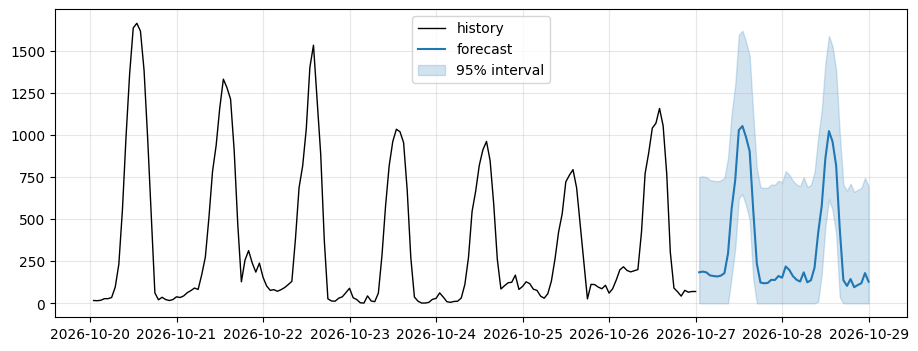

In [24]:
forecast, lower_95, upper_95 = (
    final_forecast["forecast"].to_numpy(),
    final_forecast["lower_95"].to_numpy(),
    final_forecast["upper_95"].to_numpy()
)    # <-- replace with your model's forecast and 95% interval

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend()
plt.show()

In [25]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass

format OK
saved NOSULKO_project.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.